# 모듈 2: 회수율 예측 모델 학습, 평가

- 모듈 1의 대치 전 데이터, 선택 결과를 읽고 전처리 기능을 재사용
- 타깃별 선택 피처를 유지하고 CV 평균 RMSE로 모델, 하이퍼파라미터 선택

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import json
from pathlib import Path

from module2_prediction.config import FEATURE_COLUMNS, TARGET_COLUMNS
from module2_prediction.data_loading import load_modeling_inputs, split_by_column
from module1_preprocessing.transformation import prepare_split
from module2_prediction.modeling import compare_models
from module2_prediction.tuning import tune_models_cv
from module2_prediction.evaluation import evaluate_final_model
from module2_prediction.pipeline import save_selection_report
from module2_prediction.artifacts import load_bundle
from module2_prediction.interpretation import compute_shap_values
from module2_prediction.scenario import predict_process_scenario, predict_blend_scenario
from sklearn.inspection import permutation_importance

import matplotlib
import matplotlib.pyplot as plt
get_ipython().run_line_magic('matplotlib', 'inline')
matplotlib.rcParams['font.family'] = ['Noto Sans CJK JP', 'DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False

DATA_PATH = Path('../data/processed/pre_impute_data.csv')
FIGURES_DIR = Path('../module2_prediction/reports/figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = Path('../module2_prediction/reports/final')

## 1. 데이터 로드

In [2]:
df, selection = load_modeling_inputs(DATA_PATH)
features_by_target = {t: entry['features'] for t, entry in selection['targets'].items()}
train_df, val_df, test_df = split_by_column(df)
cv_pool = pd.concat([train_df, val_df], ignore_index=True)
print(f'Train: {len(train_df)}행 / Validation: {len(val_df)}행 / Test: {len(test_df)}행')
print(f'CV 풀(Train+Validation): {len(cv_pool)}행')

Train: 294행 / Validation: 63행 / Test: 63행
CV 풀(Train+Validation): 357행


## 2. 모델 비교 (기본값, 단일 Validation 분할)

- RandomForest, XGBoost, LightGBM, ElasticNet, SVR을 동일한 feature set, 기본 하이퍼파라미터로 비교
- Test는 안 봄, 참고용 베이스라인
- 실제 모델, 하이퍼파라미터 선정은 §3의 CV 결과로 함 — 단일 분할은 분할 운에 따라 순위가 흔들릴 수 있음

In [3]:
default_results = compare_models(train_df, val_df, feature_columns=features_by_target)
pd.DataFrame(default_results).T

train_rmse    val_r2    val_mse  val_rmse   val_mae
RandomForest Ni_회수율_pct    0.931524  0.779699   6.562015  2.561643  2.045843
             Co_회수율_pct    1.092696  0.784044  10.047041  3.169707  2.334717
XGBoost      Ni_회수율_pct    0.000875  0.719371   8.358974  2.891189  2.160604
             Co_회수율_pct    0.000860  0.703182  13.809062  3.716055  2.823631
LightGBM     Ni_회수율_pct    0.707352  0.729043   8.070856  2.840925  2.220841
             Co_회수율_pct    0.814634  0.793013   9.629803  3.103192  2.271532
ElasticNet   Ni_회수율_pct    2.852932  0.754465   7.313641  2.704375  2.175827
             Co_회수율_pct    3.248475  0.776335  10.405690  3.225785  2.649315
SVR          Ni_회수율_pct    2.339728  0.770926   6.823306  2.612146  1.923732
             Co_회수율_pct    2.816725  0.766016  10.885763  3.299358  2.514245

## 3. 하이퍼파라미터 튜닝 (Stratified 5-Fold CV)

- `config.MODEL_HYPERPARAMETER_GRIDS`의 각 조합을 CV 풀(Train+Validation)에서 Stratified 5-Fold CV로 평가해 모델, 타겟별 최적값을 고름
- 단일 Validation 분할(63행)은 분할 운에 따라 순위가 흔들릴 수 있음(모듈1에서 실제로 확인됨) — 각 fold의 학습 부분만으로 대치하고 CV 평균 RMSE로 선택함. CV는 선택용 점수이며 일반화 성능은 Test로 보고함
- Test는 CV 풀에 포함하지 않음

In [4]:
cv = selection['cv']
tuned = tune_models_cv(cv_pool, feature_columns=features_by_target, n_splits=cv['n_splits'], random_state=cv['random_state'], stratify_column=cv['stratify_column'])
pd.DataFrame({key: v['metrics'] for key, v in tuned.items()}).T

val_r2   val_mse  val_rmse  val_rmse_std  \
RandomForest Ni_회수율_pct  0.817799  6.254402  2.498077      0.132357   
             Co_회수율_pct  0.804444  9.495074  3.051609      0.477962   
XGBoost      Ni_회수율_pct  0.842940  5.401855  2.322480      0.099632   
             Co_회수율_pct  0.840607  7.720265  2.758446      0.372893   
LightGBM     Ni_회수율_pct  0.841983  5.430298  2.329070      0.084625   
             Co_회수율_pct  0.834322  8.027543  2.810556      0.400498   
ElasticNet   Ni_회수율_pct  0.842030  5.440933  2.328774      0.148928   
             Co_회수율_pct  0.852126  7.087056  2.648905      0.296556   
SVR          Ni_회수율_pct  0.860694  4.792906  2.185441      0.144710   
             Co_회수율_pct  0.861709  6.642929  2.563357      0.300273   

                         val_mae_std   val_mae  train_rmse  train_rmse_std  \
RandomForest Ni_회수율_pct     0.135794  1.984042    0.932205        0.015916   
             Co_회수율_pct     0.365225  2.362417    1.165061        0.051015   
XGBoost      Ni_회수율_pct     0.117017  1.828491    1.005406        0.030397   
             Co_회수율_pct     0.255797  2.108206    1.214551        0.062765   
LightGBM     Ni_회수율_pct     0.099146  1.844232    1.346153        0.021284   
             Co_회수율_pct     0.289843  2.175600    1.848157        0.075543   
ElasticNet   Ni_회수율_pct     0.118183  1.838296    2.232912        0.045709   
             Co_회수율_pct     0.261184  2.047372    2.544159        0.074340   
SVR          Ni_회수율_pct     0.114253  1.704860    1.983383        0.047918   
             Co_회수율_pct     0.272907  1.967378    2.392132        0.075506   

                         rmse_gap  
RandomForest Ni_회수율_pct  1.565871  
             Co_회수율_pct  1.886548  
XGBoost      Ni_회수율_pct  1.317074  
             Co_회수율_pct  1.543895  
LightGBM     Ni_회수율_pct  0.982917  
             Co_회수율_pct  0.962399  
ElasticNet   Ni_회수율_pct  0.095862  
             Co_회수율_pct  0.104746  
SVR          Ni_회수율_pct  0.202058  
             Co_회수율_pct  0.171224

## 4. 최종 모델 선정 (타겟별 CV 평균 RMSE 최소 모델)

In [5]:
best_per_target = {
    target: min(
        (key for key in tuned if key[1] == target),
        key=lambda key: tuned[key]['metrics']['val_rmse']
    )
    for target in TARGET_COLUMNS
}
for target, (model_name, _) in best_per_target.items():
    p = tuned[(model_name, target)]
    print(f'{target}: {model_name}, params={p["params"]}, val_rmse={p["metrics"]["val_rmse"]:.4f}')

Ni_회수율_pct: SVR, params={'C': 10, 'gamma': 0.01, 'epsilon': 0.1}, val_rmse=2.1854
Co_회수율_pct: SVR, params={'C': 10, 'gamma': 0.01, 'epsilon': 0.1}, val_rmse=2.5634


### 선정 근거와 과적합 진단
- 모듈 1의 split을 그대로 읽고 Train+Validation 내부에서만 CV 수행
- 동일 fold의 평균 검증 RMSE 최소 모델을 타깃별 선정, MAE, R²는 보조 지표
- 학습 RMSE: 해당 fold 모델의 학습 데이터 적합 오차. 검증 RMSE와의 차이(rmse_gap)는 과적합 진단용 — 오차 차이가 작다는 이유로 모델을 재선정하지 않음. 단위는 %p
- CV RMSE는 모델, 하이퍼파라미터 선택에 사용한 점수이므로 독립 평가 점수로 해석하지 않음
- 현재 피처 비교 결과는 참고 기록이며 튜닝에는 고정 피처 사용
- CV 표준편차는 분할별 성능 변동이며, 개별 배치의 예측구간, 포함률은 미구현


,model,target,train_rmse,train_rmse_std,val_rmse,val_rmse_std,rmse_gap,val_mae,val_r2
0,RandomForest,Ni_회수율_pct,0.932205,0.015916,2.498077,0.132357,1.565871,1.984042,0.817799
1,RandomForest,Co_회수율_pct,1.165061,0.051015,3.051609,0.477962,1.886548,2.362417,0.804444
2,XGBoost,Ni_회수율_pct,1.005406,0.030397,2.322480,0.099632,1.317074,1.828491,0.842940
3,XGBoost,Co_회수율_pct,1.214551,0.062765,2.758446,0.372893,1.543895,2.108206,0.840607
4,LightGBM,Ni_회수율_pct,1.346153,0.021284,2.329070,0.084625,0.982917,1.844232,0.841983
5,LightGBM,Co_회수율_pct,1.848157,0.075543,2.810556,0.400498,0.962399,2.175600,0.834322
6,ElasticNet,Ni_회수율_pct,2.232912,0.045709,2.328774,0.148928,0.095862,1.838296,0.842030
7,ElasticNet,Co_회수율_pct,2.544159,0.074340,2.648905,0.296556,0.104746,2.047372,0.852126
8,SVR,Ni_회수율_pct,1.983383,0.047918,2.185441,0.144710,0.202058,1.704860,0.860694
9,SVR,Co_회수율_pct,2.392132,0.075506,2.563357,0.300273,0.171224,1.967378,0.861709


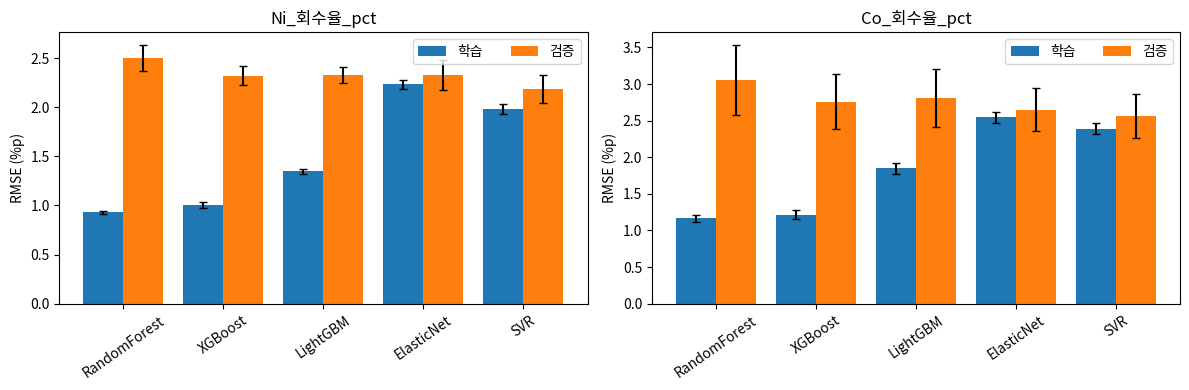

In [6]:
cv_table = save_selection_report(tuned, best_per_target, selection, MODEL_DIR)
display(cv_table[['model', 'target', 'train_rmse', 'train_rmse_std',
                  'val_rmse', 'val_rmse_std', 'rmse_gap', 'val_mae', 'val_r2']])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, target in zip(axes, TARGET_COLUMNS):
    table = cv_table[cv_table.target == target].set_index('model')
    x = np.arange(len(table))
    ax.bar(x - .2, table.train_rmse, .4, yerr=table.train_rmse_std, label='학습', capsize=3)
    ax.bar(x + .2, table.val_rmse, .4, yerr=table.val_rmse_std, label='검증', capsize=3)
    ax.set_xticks(x, table.index, rotation=35)
    ax.set(title=target, ylabel='RMSE (%p)')
    ax.legend(loc='upper right', ncol=2)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'train_validation_rmse.png')
plt.show()
plt.close(fig)


## 5. 최종 Test 평가 (선정 완료 후 Train+Validation 재학습)

In [7]:
final_results = {}
for target, (model_name, _) in best_per_target.items():
    params = tuned[(model_name, target)]['params']
    result = evaluate_final_model(
        train_df, val_df, test_df,
        model_name=model_name, model_params=params,
        target_columns=[target], feature_columns=features_by_target[target], output_dir=MODEL_DIR,
    )
    final_results[target] = dict(model=model_name, params=params, primary_metric='rmse', features=features_by_target[target], **tuned[(model_name, target)]['metrics'], **result[target])

(MODEL_DIR / 'results.json').write_text(json.dumps(final_results, ensure_ascii=False, indent=2), encoding='utf-8')
pd.DataFrame(final_results).T

,model,params,primary_metric,features,val_r2,val_mse,val_rmse,val_rmse_std,val_mae_std,val_mae,train_rmse,train_rmse_std,rmse_gap,test_r2,test_mse,test_rmse,test_mae
Ni_회수율_pct,SVR,"{'C': 10, 'gamma': 0.01, 'epsilon': 0.1}",rmse,"[Ni_함량_pct, Co_함량_pct, Li_함량_pct, Mn_함량_pct, C...",0.860694,4.792906,2.185441,0.14471,0.114253,1.70486,1.983383,0.047918,0.202058,0.860363,5.222947,2.285377,1.738007
Co_회수율_pct,SVR,"{'C': 10, 'gamma': 0.01, 'epsilon': 0.1}",rmse,"[Ni_함량_pct, Co_함량_pct, Li_함량_pct, Mn_함량_pct, C...",0.861709,6.642929,2.563357,0.300273,0.272907,1.967378,2.392132,0.075506,0.171224,0.870034,5.419133,2.327903,1.874743


### 선정 결과 해석

아래는 §4에서 고른 모델의 Test 성능과, 같은 타깃에서 차순위였던 모델과의 CV 검증 RMSE 차이임.

In [8]:
for target, (model_name, _) in best_per_target.items():
    r = final_results[target]
    ranked = sorted((k for k in tuned if k[1] == target), key=lambda k: tuned[k]['metrics']['val_rmse'])
    runner_up = ranked[1] if len(ranked) > 1 else None
    print(f"{target}: {model_name} 선정, params={r['params']}")
    print(f"  Test RMSE={r['test_rmse']:.3f}%p, MAE={r['test_mae']:.3f}%p, R2={r['test_r2']:.3f}")
    if runner_up is not None:
        gap = tuned[runner_up]['metrics']['val_rmse'] - tuned[(model_name, target)]['metrics']['val_rmse']
        print(f"  차순위 {runner_up[0]} 대비 검증 RMSE {gap:.3f}%p 더 낮음(선정 기준)")

Ni_회수율_pct: SVR 선정, params={'C': 10, 'gamma': 0.01, 'epsilon': 0.1}
  Test RMSE=2.285%p, MAE=1.738%p, R2=0.860
  차순위 XGBoost 대비 검증 RMSE 0.137%p 더 낮음(선정 기준)
Co_회수율_pct: SVR 선정, params={'C': 10, 'gamma': 0.01, 'epsilon': 0.1}
  Test RMSE=2.328%p, MAE=1.875%p, R2=0.870
  차순위 ElasticNet 대비 검증 RMSE 0.086%p 더 낮음(선정 기준)


## 6. Test 성능 심화 분석 (등급별 오차, 단순 기준선 비교)
- 등급별 오차: `{target}_predictions.csv`에 원료등급을 붙여 A/B/C별 RMSE, MAE 비교
  - 전체 평균 하나만 보면 특정 등급에서 유독 못 맞추는지 가려질 수 있음
  - 등급 단독 성능이 좋아도 7:3 혼합 배치의 정확도가 검증되는 것은 아님(§9)
- 단순 기준선: 원료, 공정 정보를 전혀 쓰지 않고 Train+Validation 평균만 예측하는
  `DummyRegressor`와 비교해, 실제 모델이 입력 정보로 얼마나 개선됐는지 확인
- 평균 부호 오차(%p) = 평균(예측값 - 실제값) — 양수면 평균적으로 과대예측, 음수면 과소예측.
  개별 배치의 과대, 과소는 섞여 있을 수 있으며, 이 값은 그 합산 방향만 나타냄


In [9]:
from sklearn.dummy import DummyRegressor

grade_error_rows = []
baseline_rows = []
for target in TARGET_COLUMNS:
    predictions = pd.read_csv(MODEL_DIR / f'{target}_predictions.csv')
    predictions = predictions.merge(
        test_df[['배치ID', '원료등급']].rename(columns={'배치ID': 'batch_id'}),
        on='batch_id', validate='one_to_one',
    )
    if set(predictions['batch_id']) != set(test_df['배치ID']):
        raise ValueError(f'{target}: 예측 CSV와 Test 배치ID 집합이 다름')

    error = predictions['prediction'] - predictions['actual']

    for grade, group in predictions.groupby('원료등급'):
        g_error = group['prediction'] - group['actual']
        grade_error_rows.append(dict(
            target=target, grade=grade, n=len(group),
            rmse=float(np.sqrt((g_error ** 2).mean())),
            mae=float(g_error.abs().mean()),
        ))

    baseline = DummyRegressor(strategy='mean').fit(cv_pool[[]], cv_pool[target])
    baseline_preds = baseline.predict(test_df[[]])
    baseline_rmse = float(np.sqrt(((baseline_preds - test_df[target]) ** 2).mean()))
    model_rmse = final_results[target]['test_rmse']
    baseline_rows.append(dict(
        target=target, baseline_rmse=baseline_rmse, model_rmse=model_rmse,
        rmse_reduction_pct=100 * (1 - model_rmse / baseline_rmse),
        mean_signed_error_pctp=float(error.mean()),
    ))

grade_error_table = pd.DataFrame(grade_error_rows)
grade_error_table.to_csv(MODEL_DIR / 'test_error_by_grade.csv', index=False)
display(grade_error_table)

baseline_table = pd.DataFrame(baseline_rows)
baseline_table.to_csv(MODEL_DIR / 'baseline_comparison.csv', index=False)
display(baseline_table)


,target,grade,n,rmse,mae
0,Ni_회수율_pct,A,22,2.368301,1.890589
1,Ni_회수율_pct,B,24,2.426680,1.863220
2,Ni_회수율_pct,C,17,1.945134,1.363779
3,Co_회수율_pct,A,22,1.952689,1.553727
4,Co_회수율_pct,B,24,2.549816,2.039892
5,Co_회수율_pct,C,17,2.443263,2.057025


,target,baseline_rmse,model_rmse,rmse_reduction_pct,mean_signed_error_pctp
0,Ni_회수율_pct,6.116030,2.285377,62.633003,0.178392
1,Co_회수율_pct,6.475557,2.327903,64.050921,0.183386


## 7. SHAP 중요도와 permutation importance 비교
- 최종 평가에서 저장한 동일 모델을 불러옴
- 개발 데이터에서 고정 추출한 최대 100행을 배경으로 사용, Test 입력의 예측을 설명 — Test 정답은 SHAP 계산에 미사용
- 평균 절대 SHAP 값은 전체 중요도(%p), beeswarm은 배치별 기여 방향과 분포를 나타냄
- Test에서 SHAP 중요도와 permutation importance를 비교해 최종 모델의 피처 의존성을 살펴봄
- permutation importance: 같은 Test 입력에서 피처 하나를 섞었을 때 평균 RMSE가 얼마나 달라지는지(%p)만 봄
  - 0에 가깝거나 음수인 값 → 이 Test에서 성능 악화가 관찰되지 않았다는 뜻
  - 원변수와 파생변수가 겹치는 경우, 그 값만으로 피처를 빼도 된다고 판단하기는 어려움
- 이 결과로 피처나 모델을 재선택하지 않음


In [10]:
train_val_df = prepare_split(cv_pool, cv_pool)
test_prepared = prepare_split(cv_pool, test_df)
background_positions = np.random.default_rng(42).choice(len(train_val_df), size=min(100, len(train_val_df)), replace=False)
pd.DataFrame({'batch_id': cv_pool.iloc[background_positions]['배치ID'].to_numpy()}).to_csv(
    MODEL_DIR / 'shap_background_batches.csv', index=False)
interpretation_models = {}
shap_by_target = {}
importance_by_target = {}
perm_importance_by_target = {}
for target in TARGET_COLUMNS:
    bundle = load_bundle(MODEL_DIR / f'{target}.joblib')
    model = bundle['model']
    columns = bundle['features']
    interpretation_models[target] = model
    X = test_prepared[columns]
    background = train_val_df.iloc[background_positions][columns]
    values = compute_shap_values(model, X, background=background)
    shap_by_target[target] = values
    importance_by_target[target] = pd.Series(np.abs(values).mean(axis=0), index=columns)
    pd.DataFrame(values, columns=columns, index=test_df['배치ID']).to_csv(MODEL_DIR / f'{target}_shap_values.csv')

    result = permutation_importance(
        model, X, test_prepared[target],
        scoring='neg_root_mean_squared_error', n_repeats=10, random_state=42,
    )
    perm_importance_by_target[target] = pd.Series(result.importances_mean, index=X.columns)
importance_table = pd.DataFrame(importance_by_target)
importance_table.to_csv(MODEL_DIR / 'shap_importance.csv', index_label='feature')
perm_importance_table = pd.DataFrame(perm_importance_by_target)
perm_importance_table.to_csv(MODEL_DIR / 'permutation_importance.csv', index_label='feature')
combined_importance = pd.concat(
    {'SHAP_절대평균': importance_table, '퍼뮤테이션_RMSE증가_pctp': perm_importance_table},
    axis=1,
)
display(combined_importance.round(4))


PermutationExplainer explainer:  38%|███▊      | 24/63 [00:00<?, ?it/s]

PermutationExplainer explainer:  41%|████▏     | 26/63 [00:10<00:08,  4.62it/s]

PermutationExplainer explainer:  43%|████▎     | 27/63 [00:11<00:11,  3.23it/s]

PermutationExplainer explainer:  44%|████▍     | 28/63 [00:11<00:12,  2.82it/s]

PermutationExplainer explainer:  46%|████▌     | 29/63 [00:12<00:13,  2.61it/s]

PermutationExplainer explainer:  48%|████▊     | 30/63 [00:12<00:13,  2.50it/s]

... (74 outputs left out)

PermutationExplainer explainer: 100%|██████████| 63/63 [00:27<00:00,  2.27it/s]

PermutationExplainer explainer: 64it [00:27,  2.27it/s]                        

PermutationExplainer explainer: 64it [00:27,  1.48it/s]

SHAP_절대평균            퍼뮤테이션_RMSE증가_pctp           
                      Ni_회수율_pct Co_회수율_pct        Ni_회수율_pct Co_회수율_pct
Ni_함량_pct                 0.0879     0.1873            0.0099     0.0866
Co_함량_pct                 0.1760     0.0641            0.0273     0.0171
Li_함량_pct                 0.0644     0.1970            0.0548     0.0616
Mn_함량_pct                 0.2302     0.2826            0.0263     0.0001
Cu_불순물_pct                0.4408     1.0753            0.1669     0.4811
Fe_불순물_pct                0.3203     0.5970            0.1081     0.1007
Al_불순물_pct                0.6392     0.7366            0.2461     0.0857
침출온도_C                    1.5404     2.0337            1.2310     1.4510
침출시간_hr                   0.5658     0.6552            0.2818     0.2561
원료투입량_kg                  0.4982     0.6806            0.1447     0.1550
황산투입량_L                   1.0397     0.8900            0.3150     0.2886
acid_to_ore_ratio         1.0710     0.9648            0.5093     0.3485
leach_intensity           1.1806     1.0806            0.9894     0.5838
total_impurity_pct        0.5132     0.8707            0.1998     0.2333
feed_impurity_g_per_l     0.7644     0.8171            0.3151     0.1663

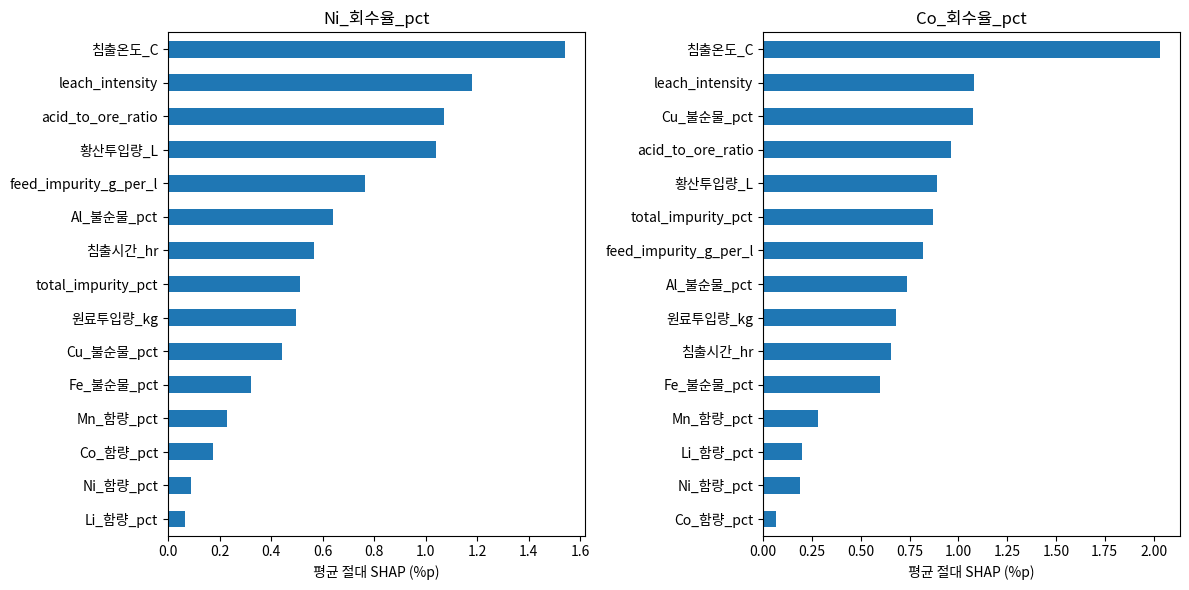

/tmp/ipykernel_1582444/412287751.py:12: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_by_target[target], test_prepared[features_by_target[target]], show=False)


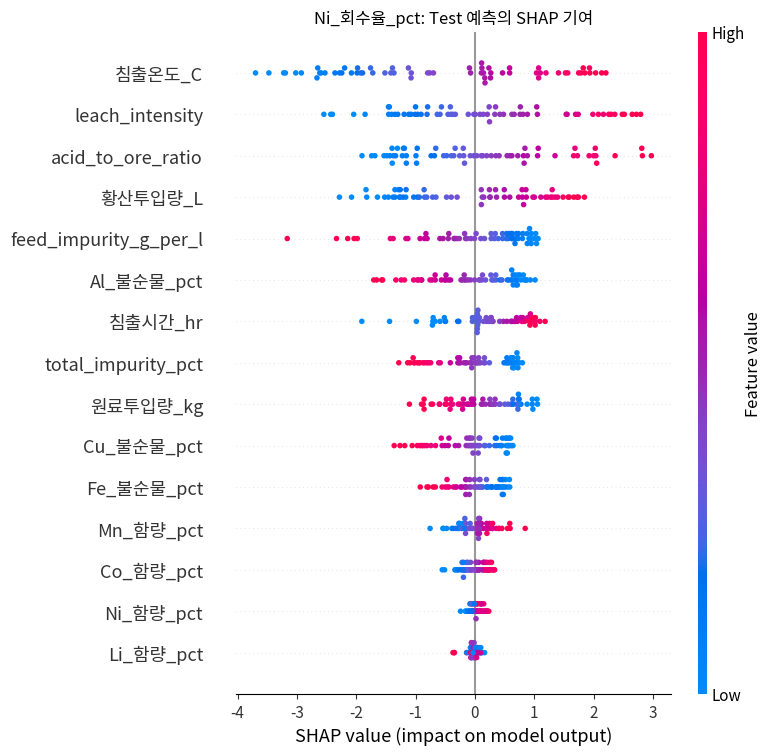

/tmp/ipykernel_1582444/412287751.py:12: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_by_target[target], test_prepared[features_by_target[target]], show=False)


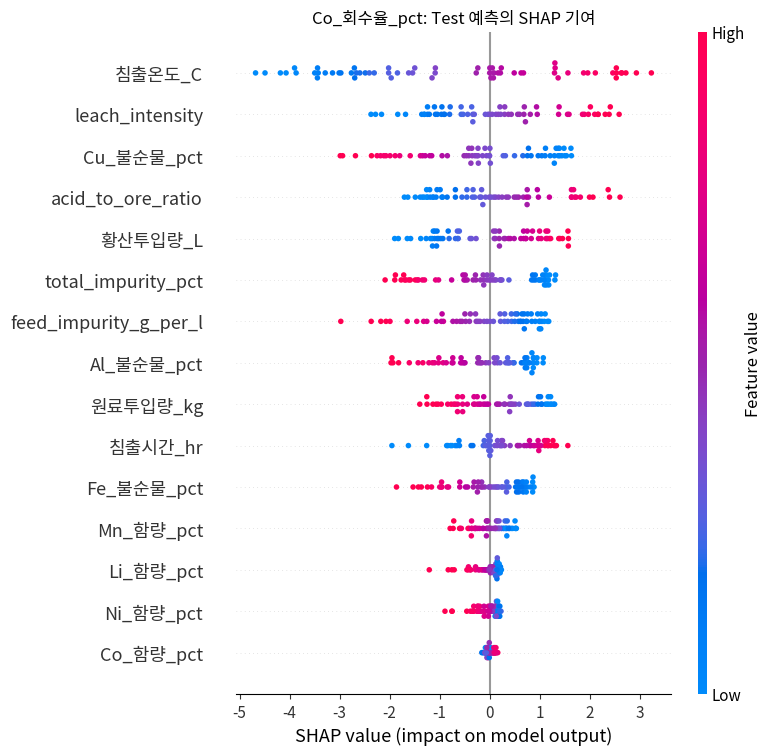

In [11]:
import shap
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, target in zip(axes, TARGET_COLUMNS):
    importance_table[target].sort_values().plot.barh(ax=ax)
    ax.set(title=target, xlabel='평균 절대 SHAP (%p)')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'shap_importance.png')
plt.show()
plt.close(fig)
for target in TARGET_COLUMNS:
    plt.figure()
    shap.summary_plot(shap_by_target[target], test_prepared[features_by_target[target]], show=False)
    plt.title(f'{target}: Test 예측의 SHAP 기여')
    plt.savefig(FIGURES_DIR / f'shap_summary_{target}.png', bbox_inches='tight')
    plt.show()
    plt.close()


### 핵심 인자 해석과 한계
- 아래 표: 타깃별 상위 3개 변수의 중요도 + 낮은 값/높은 값 집단의 평균 SHAP
  - 두 집단은 각 변수의 Test 25, 75 분위수로 구분, 집단 간 차이는 관측된 연관성
  - 다른 조건을 통제한 효과나 단조성을 증명하지 않으므로 beeswarm과 함께 해석

공정 관점에서 검토할 가설:
- 침출온도, 침출시간, 침출강도: 반응 진행 조건을 요약. 온도 상승의 기여 방향이 양수인지 확인하되,
  온도×시간과 중복된 정보를 개별 효과로 더하지 않음
- 산-광석비, 황산투입량: 원료 대비 산 용액 공급 조건과 관련. 산 농도가 입력에 없으므로
  용액 부피를 유효 산 몰수나 산 소비량으로 해석하지 않음
- 총불순물, 개별 불순물, 산용액당불순물량: 원료 조성과 산 공급의 관계를 나타냄.
  경쟁 반응이나 산 소비와 연결될 가능성은 검토 가설이며 실제 원인은 실험으로 확인 필요

- 이 설명은 도메인 검토를 위한 가설 — 문헌, 운전 기록, 혼합 실험 확인 전에는 도메인 지식과의
  일치나 새로운 발견을 확정하지 않음
- 상관된 원변수, 파생변수를 독립적으로 변화시키는 SHAP 계산에는 현실에 없는 조합이 포함될 수 있음


In [12]:
rows = []
for target in TARGET_COLUMNS:
    columns = features_by_target[target]
    for feature in importance_table[target].nlargest(3).index:
        x = test_prepared[feature]
        contribution = shap_by_target[target][:, columns.index(feature)]
        low, high = x.quantile([.25, .75])
        low_mean = float(contribution[x <= low].mean())
        high_mean = float(contribution[x >= high].mean())
        rows.append(dict(target=target, feature=feature,
            mean_abs_shap=importance_table.loc[feature, target],
            low_threshold=low, high_threshold=high,
            low_group_mean_shap=low_mean, high_group_mean_shap=high_mean,
            high_minus_low_shap=high_mean-low_mean))
domain_summary = pd.DataFrame(rows)
domain_summary.to_csv(MODEL_DIR / 'shap_top_factors.csv', index=False)
display(domain_summary.round(4))


,target,feature,mean_abs_shap,low_threshold,high_threshold,low_group_mean_shap,high_group_mean_shap,high_minus_low_shap
0,Ni_회수율_pct,침출온도_C,1.5404,50.4000,76.1000,-2.7348,1.6467,4.3815
1,Ni_회수율_pct,leach_intensity,1.1806,197.0672,376.8930,-1.5618,2.1160,3.6778
2,Ni_회수율_pct,acid_to_ore_ratio,1.0710,4.1863,8.8074,-1.3854,1.8975,3.2829
3,Co_회수율_pct,침출온도_C,2.0337,50.4000,76.1000,-3.5562,2.2353,5.7916
4,Co_회수율_pct,leach_intensity,1.0806,197.0672,376.8930,-1.4429,1.9222,3.3651
5,Co_회수율_pct,Cu_불순물_pct,1.0753,0.9150,2.6700,1.3844,-2.0046,-3.3890


### SHAP 상위 변수 해석

In [13]:
for target in TARGET_COLUMNS:
    top3 = importance_table[target].nlargest(3)
    print(f'{target} SHAP 상위 3: ' + ', '.join(f'{f}(절대평균 {v:.3f}%p)' for f, v in top3.items()))
    for feature in top3.index:
        row = domain_summary[(domain_summary.target == target) & (domain_summary.feature == feature)].iloc[0]
        comparison = '높음' if row['high_minus_low_shap'] > 0 else '낮음'
        print(f"  {feature}: 하위 25% 집단 평균 SHAP {row['low_group_mean_shap']:.3f}, "
              f"상위 25% 집단 평균 SHAP {row['high_group_mean_shap']:.3f} "
              f"(상위 25% 집단의 평균 SHAP이 하위 25% 집단보다 {comparison} — 단조성을 증명하지 않음)")

Ni_회수율_pct SHAP 상위 3: 침출온도_C(절대평균 1.540%p), leach_intensity(절대평균 1.181%p), acid_to_ore_ratio(절대평균 1.071%p)
  침출온도_C: 하위 25% 집단 평균 SHAP -2.735, 상위 25% 집단 평균 SHAP 1.647 (상위 25% 집단의 평균 SHAP이 하위 25% 집단보다 높음 — 단조성을 증명하지 않음)
  leach_intensity: 하위 25% 집단 평균 SHAP -1.562, 상위 25% 집단 평균 SHAP 2.116 (상위 25% 집단의 평균 SHAP이 하위 25% 집단보다 높음 — 단조성을 증명하지 않음)
  acid_to_ore_ratio: 하위 25% 집단 평균 SHAP -1.385, 상위 25% 집단 평균 SHAP 1.898 (상위 25% 집단의 평균 SHAP이 하위 25% 집단보다 높음 — 단조성을 증명하지 않음)
Co_회수율_pct SHAP 상위 3: 침출온도_C(절대평균 2.034%p), leach_intensity(절대평균 1.081%p), Cu_불순물_pct(절대평균 1.075%p)
  침출온도_C: 하위 25% 집단 평균 SHAP -3.556, 상위 25% 집단 평균 SHAP 2.235 (상위 25% 집단의 평균 SHAP이 하위 25% 집단보다 높음 — 단조성을 증명하지 않음)
  leach_intensity: 하위 25% 집단 평균 SHAP -1.443, 상위 25% 집단 평균 SHAP 1.922 (상위 25% 집단의 평균 SHAP이 하위 25% 집단보다 높음 — 단조성을 증명하지 않음)
  Cu_불순물_pct: 하위 25% 집단 평균 SHAP 1.384, 상위 25% 집단 평균 SHAP -2.005 (상위 25% 집단의 평균 SHAP이 하위 25% 집단보다 낮음 — 단조성을 증명하지 않음)


## 8. 공정조건별 변화 분석

- 침출온도_C, 침출시간_hr을 각각 바꿔가며 Ni_회수율, Co_회수율 예측값 변화 확인
  (나머지 변수는 고정, 2타깃×2변수=4개 조합 전부 확인)
- 공정조건(PROCESS_COLUMNS) 변경이므로 leach_intensity(=온도×시간)를 함께 재계산하는
  `predict_process_scenario` 사용
- `partial_dependence`는 파생변수를 그대로 둬서, 값만 바꾸면 학습 데이터의 파생식과
  모순되는 입력이 되므로 여기서는 쓰지 않음

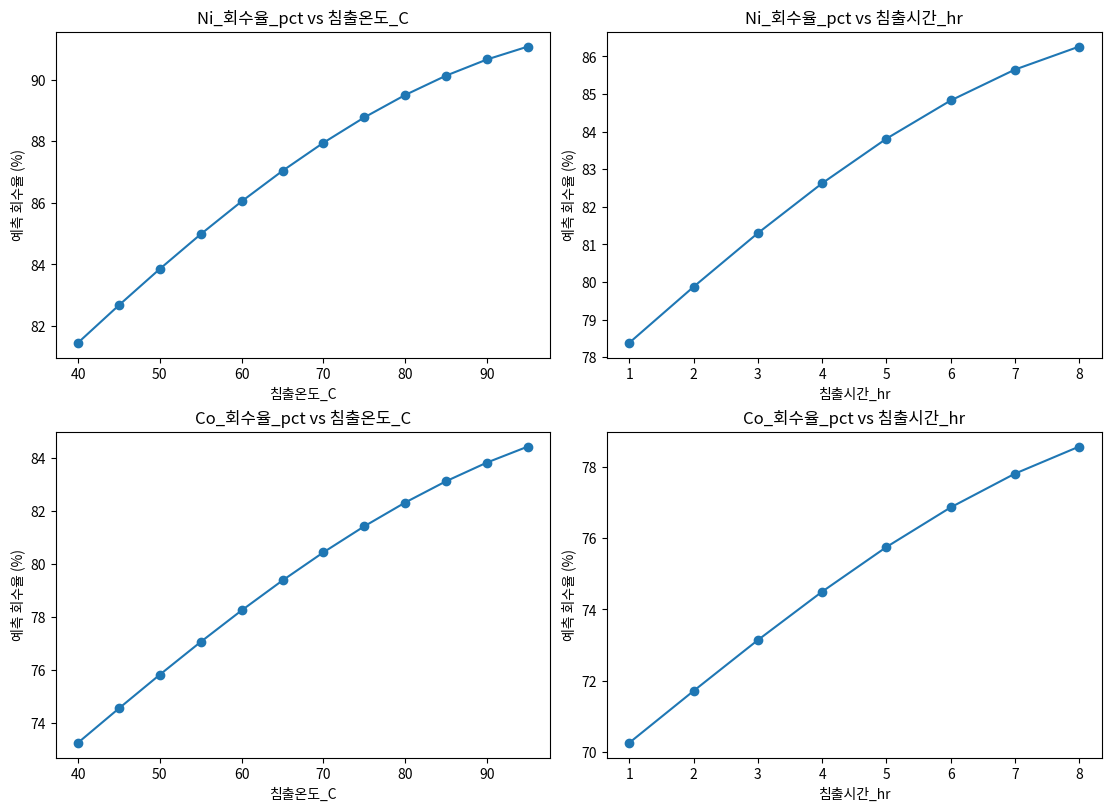

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8), constrained_layout=True)
scenarios = [('침출온도_C', list(range(40, 96, 5))), ('침출시간_hr', list(range(1, 9)))]
scenario_results = {}
for row, target in enumerate(TARGET_COLUMNS):
    model = interpretation_models[target]
    base_row = train_val_df.iloc[0]
    for col, (feature, values) in enumerate(scenarios):
        pd_result = predict_process_scenario(model, base_row, feature=feature, values=values, feature_columns=features_by_target[target])
        scenario_results[(target, feature)] = pd_result
        ax = axes[row, col]
        pd_result.plot(x=feature, y='prediction', marker='o', ax=ax, legend=False, title=f'{target} vs {feature}')
        ax.set_ylabel('예측 회수율 (%)')
fig.savefig(FIGURES_DIR / 'process_condition_sensitivity.png')
plt.show()
plt.close(fig)

### 공정조건별 예측 경향 해석

In [15]:
for (target, feature), pd_result in scenario_results.items():
    pred = pd_result['prediction']
    monotonic = '증가' if pred.is_monotonic_increasing else ('감소' if pred.is_monotonic_decreasing else '비단조')
    print(f'{target} vs {feature}: {pred.iloc[0]:.2f}% -> {pred.iloc[-1]:.2f}% '
          f'(범위 {pred.max()-pred.min():.2f}%p, {monotonic})')

Ni_회수율_pct vs 침출온도_C: 81.46% -> 91.07% (범위 9.61%p, 증가)
Ni_회수율_pct vs 침출시간_hr: 78.39% -> 86.26% (범위 7.87%p, 증가)
Co_회수율_pct vs 침출온도_C: 73.24% -> 84.42% (범위 11.18%p, 증가)
Co_회수율_pct vs 침출시간_hr: 70.25% -> 78.58% (범위 8.33%p, 증가)


## 9. 7:3 혼합 시나리오 예측

- 실제 성분 분석값을 동일 질량 기준으로 7:3 혼합, 이번 배치의 운전조건 적용
- 아래 값은 사용법 설명용 가상 입력 — 오늘의 측정값이 아님, 실제 사용 시 두 원료 분석값과 운전조건을 교체
- 혼합 배치 정확도는 실험으로 검증 필요

In [16]:
target = TARGET_COLUMNS[0]
model = interpretation_models[target]

# 설명용 가상 분석값(wt%, 동일 질량 기준). 오늘 입고된 원료의 측정값으로 교체하세요.
composition_a = {'Ni_함량_pct': 20, 'Co_함량_pct': 8, 'Li_함량_pct': 4, 'Mn_함량_pct': 10, 'Cu_불순물_pct': 1, 'Fe_불순물_pct': 1, 'Al_불순물_pct': 1}
composition_c = {'Ni_함량_pct': 10, 'Co_함량_pct': 4, 'Li_함량_pct': 3, 'Mn_함량_pct': 10, 'Cu_불순물_pct': 4, 'Fe_불순물_pct': 4, 'Al_불순물_pct': 5}
blend_prediction = predict_blend_scenario(model, composition_a, composition_c, ratio_a=0.7, total_ore_kg=100, acid_l=600, temperature_c=70, time_hr=4, feature_columns=features_by_target[target])
print(f'가상 입력 예시 A:C = 7:3 혼합 예상 {target}: {blend_prediction:.2f}%')

가상 입력 예시 A:C = 7:3 혼합 예상 Ni_회수율_pct: 84.85%


## 10. 예측값 비교 및 황산량 시나리오

- 저장한 최종 모델의 평가 결과와 공정조건별 예측 확인함
- 모델 해석은 인과관계를 의미하지 않음
- 현재 공식 실행에서 Test를 선택에 쓰는 경로는 발견되지 않았고, 과거 피처 선택에 현재 Test 배치가 쓰였는지는 미확인. 미래 배치는 시간순 미평가이며, 7:3 혼합은 실측 미검증이다.

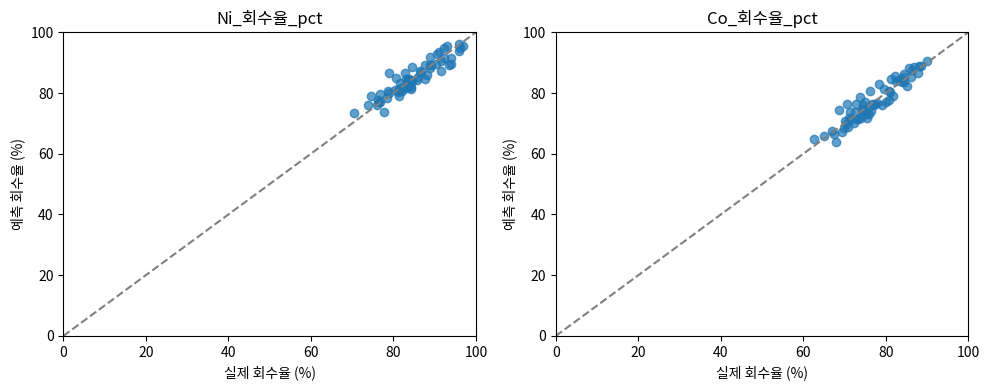

,황산투입량_L,prediction
0,400,77.709059
1,600,80.406431
2,800,82.486051
3,1000,84.220645
4,1200,85.676891
5,1500,87.353065


,황산투입량_L,prediction
0,400,70.352402
1,600,72.787405
2,800,74.723921
3,1000,76.352001
4,1200,77.725531
5,1500,79.320210


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, target in zip(axes, TARGET_COLUMNS):
    predictions = pd.read_csv(MODEL_DIR / f'{target}_predictions.csv')
    ax.scatter(predictions['actual'], predictions['prediction'], alpha=0.7)
    ax.plot([0, 100], [0, 100], '--', color='gray')
    ax.set(xlim=(0, 100), ylim=(0, 100), xlabel='실제 회수율 (%)', ylabel='예측 회수율 (%)', title=target)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'actual_vs_predicted.png')
plt.show()
for target in TARGET_COLUMNS:
    display(predict_process_scenario(interpretation_models[target], base_row,
        feature='황산투입량_L', values=[400, 600, 800, 1000, 1200, 1500],
        feature_columns=features_by_target[target]))
